# Iris Species Classification - Machine Learning Task

**Objective:** Build a machine learning model to classify Iris flower species (
Iris-setosa, Iris-versicolor, Iris-virginica) using sepal and petal measurements.

**Dataset:** `Iris.csv` (150 samples, 4 features, 3 target classes) - easily downloadable from the UCI Machine Learning Repository / Kaggle.

**Framework:** Python + scikit-learn (ML), pandas/numpy (data handling), matplotlib/seaborn (visualization).


In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, cross_val_score, GridSearchCV
from sklearn.preprocessing import LabelEncoder, StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay,
)

from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import SVC
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.neural_network import MLPClassifier

sns.set(style="whitegrid")
%matplotlib inline


## 1. Load the Dataset

Load `Iris.csv` from the working directory and inspect its structure.

In [ ]:
df = pd.read_csv("Iris.csv")

print("Shape:", df.shape)
print("\nFirst 5 rows:")
display(df.head())
print("\nData types & missing values:")
print(df.info())
print("\nMissing values per column:")
print(df.isnull().sum())
print("\nSpecies distribution:")
print(df["Species"].value_counts())


Shape: (150, 6)

First 5 rows:


,Id,SepalLengthCm,SepalWidthCm,PetalLengthCm,PetalWidthCm,Species
0,1,5.1,3.5,1.4,0.2,Iris-setosa
1,2,4.9,3.0,1.4,0.2,Iris-setosa
2,3,4.7,3.2,1.3,0.2,Iris-setosa
3,4,4.6,3.1,1.5,0.2,Iris-setosa
4,5,5.0,3.6,1.4,0.2,Iris-setosa



Data types & missing values:
<class 'pandas.DataFrame'>
RangeIndex: 150 entries, 0 to 149
Data columns (total 6 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   Id             150 non-null    int64  
 1   SepalLengthCm  150 non-null    float64
 2   SepalWidthCm   150 non-null    float64
 3   PetalLengthCm  150 non-null    float64
 4   PetalWidthCm   150 non-null    float64
 5   Species        150 non-null    str    
dtypes: float64(4), int64(1), str(1)
memory usage: 7.2 KB
None

Missing values per column:
Id               0
SepalLengthCm    0
SepalWidthCm     0
PetalLengthCm    0
PetalWidthCm     0
Species          0
dtype: int64

Species distribution:
Species
Iris-setosa        50
Iris-versicolor    50
Iris-virginica     50
Name: count, dtype: int64


## 2. Exploratory Data Analysis (EDA)

Summarize feature statistics and visualize distributions/relationships across species.

In [3]:
feature_cols = ["SepalLengthCm", "SepalWidthCm", "PetalLengthCm", "PetalWidthCm"]

print("\nDescriptive statistics:")
display(df[feature_cols].describe())

print("\nFeature means by species:")
display(df.groupby("Species")[feature_cols].mean())



Descriptive statistics:


,SepalLengthCm,SepalWidthCm,PetalLengthCm,PetalWidthCm
count,150.000000,150.000000,150.000000,150.000000
mean,5.843333,3.054000,3.758667,1.198667
std,0.828066,0.433594,1.764420,0.763161
min,4.300000,2.000000,1.000000,0.100000
25%,5.100000,2.800000,1.600000,0.300000
50%,5.800000,3.000000,4.350000,1.300000
75%,6.400000,3.300000,5.100000,1.800000
max,7.900000,4.400000,6.900000,2.500000



Feature means by species:


,SepalLengthCm,SepalWidthCm,PetalLengthCm,PetalWidthCm
Species,,,,
Iris-setosa,5.006,3.418,1.464,0.244
Iris-versicolor,5.936,2.770,4.260,1.326
Iris-virginica,6.588,2.974,5.552,2.026


C:\Users\opolot\AppData\Local\Temp\ipykernel_15204\2434447211.py:4: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(data=df, x="Species", order=["Iris-setosa", "Iris-versicolor", "Iris-virginica"], palette="Set2")


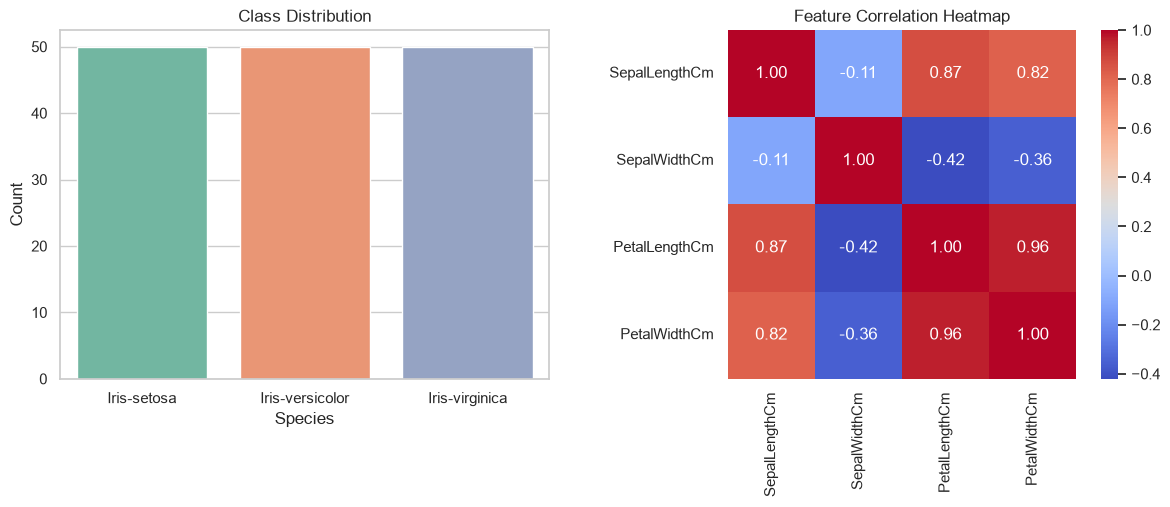

In [4]:
plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
sns.countplot(data=df, x="Species", order=["Iris-setosa", "Iris-versicolor", "Iris-virginica"], palette="Set2")
plt.title("Class Distribution")
plt.xlabel("Species")
plt.ylabel("Count")

plt.subplot(1, 2, 2)
corr = df[feature_cols].corr()
sns.heatmap(corr, annot=True, cmap="coolwarm", fmt=".2f", square=True)
plt.title("Feature Correlation Heatmap")

plt.tight_layout()
plt.show()


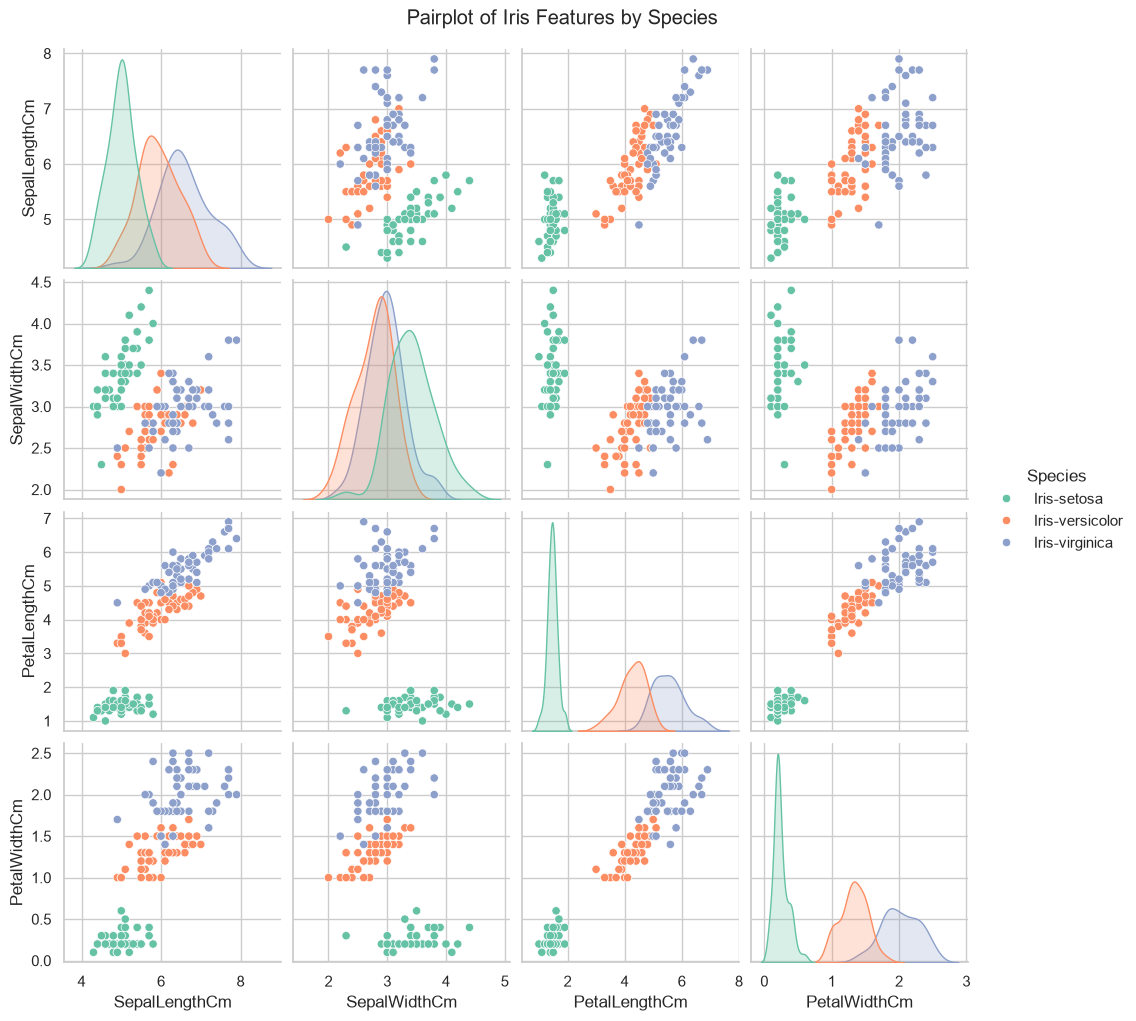

In [5]:
sns.pairplot(df, hue="Species", vars=feature_cols, palette="Set2", height=2.5)
plt.suptitle("Pairplot of Iris Features by Species", y=1.02)
plt.show()


## 3. Data Preprocessing

- Encode species labels to integers.
- Split into train (80%) / test (20%) sets with stratification.
- Standardize features (zero mean, unit variance).

In [6]:
X = df[feature_cols].values
y = df["Species"].values

le = LabelEncoder()
y_encoded = le.fit_transform(y)
class_names = le.classes_
print("Class mapping:", dict(zip(class_names, range(len(class_names)))))

X_train, X_test, y_train, y_test = train_test_split(
    X, y_encoded, test_size=0.2, random_state=42, stratify=y_encoded
)
print("Train samples:", X_train.shape[0], "| Test samples:", X_test.shape[0])
print("Train class distribution:", np.bincount(y_train))
print("Test class distribution:", np.bincount(y_test))


Class mapping: {'Iris-setosa': 0, 'Iris-versicolor': 1, 'Iris-virginica': 2}
Train samples: 120 | Test samples: 30
Train class distribution: [40 40 40]
Test class distribution: [10 10 10]


## 4. Model Training & Comparison

Train and evaluate multiple classifiers. Pipelines include `StandardScaler` where needed.
Models compared:
- Logistic Regression
- k-Nearest Neighbors
- Support Vector Machine
- Decision Tree
- Random Forest
- Multi-Layer Perceptron (neural network)

In [7]:
models = {
    "Logistic Regression": LogisticRegression(max_iter=1000, random_state=42),
    "k-Nearest Neighbors": KNeighborsClassifier(n_neighbors=5),
    "Support Vector Machine": SVC(kernel="rbf", random_state=42, probability=True),
    "Decision Tree": DecisionTreeClassifier(random_state=42),
    "Random Forest": RandomForestClassifier(n_estimators=200, random_state=42),
    "MLP (Neural Network)": MLPClassifier(
        hidden_layer_sizes=(16, 8),
        max_iter=1000,
        random_state=42,
        early_stopping=True,
    ),
}

results = []
trained_models = {}

for name, model in models.items():
    pipe = Pipeline([("scaler", StandardScaler()), ("clf", model)])
    pipe.fit(X_train, y_train)
    y_pred = pipe.predict(X_test)
    acc = accuracy_score(y_test, y_pred)
    cv_mean = cross_val_score(pipe, X_train, y_train, cv=5, scoring="accuracy").mean()
    results.append({"Model": name, "Test Accuracy": acc, "5-Fold CV Mean": cv_mean})
    trained_models[name] = pipe

results_df = pd.DataFrame(results).sort_values("Test Accuracy", ascending=False).reset_index(drop=True)
display(results_df)

best_name = results_df.iloc[0]["Model"]
print("\nBest model:", best_name)


C:\Users\opolot\AppData\Local\Programs\Python\Python312\Lib\site-packages\sklearn\svm\_base.py:236: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(
C:\Users\opolot\AppData\Local\Programs\Python\Python312\Lib\site-packages\sklearn\svm\_base.py:236: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(
C:\Users\opolot\AppData\Local\Programs\Python\Python312\Lib\site-packages\sklearn\svm\_base.py:236: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(
C:\Users\opolot\AppData\Local\Programs\Python\Python312\Lib\site-packages\sklearn\

,Model,Test Accuracy,5-Fold CV Mean
0,Support Vector Machine,0.966667,0.966667
1,Logistic Regression,0.933333,0.958333
2,k-Nearest Neighbors,0.933333,0.966667
3,Decision Tree,0.900000,0.941667
4,Random Forest,0.900000,0.950000
5,MLP (Neural Network),0.333333,0.333333



Best model: Support Vector Machine


=== Best Model: Support Vector Machine ===
Test Accuracy: 0.9667

Classification Report:
                 precision    recall  f1-score   support

    Iris-setosa       1.00      1.00      1.00        10
Iris-versicolor       1.00      0.90      0.95        10
 Iris-virginica       0.91      1.00      0.95        10

       accuracy                           0.97        30
      macro avg       0.97      0.97      0.97        30
   weighted avg       0.97      0.97      0.97        30



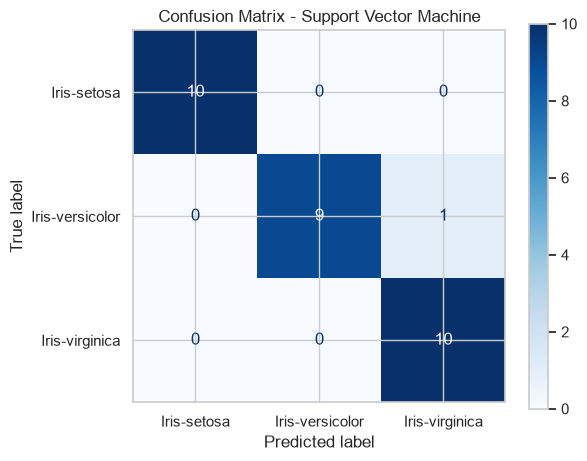

In [8]:
best_model = trained_models[best_name]
y_pred_best = best_model.predict(X_test)

print("=== Best Model: %s ===" % best_name)
print("Test Accuracy: %.4f" % accuracy_score(y_test, y_pred_best))
print("\nClassification Report:")
print(classification_report(y_test, y_pred_best, target_names=[str(c) for c in class_names]))

cm = confusion_matrix(y_test, y_pred_best)
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=class_names)
fig, ax = plt.subplots(figsize=(6, 5))
disp.plot(ax=ax, cmap="Blues", values_format="d")
plt.title("Confusion Matrix - %s" % best_name)
plt.show()


## 5. Model Accuracy Comparison

Bar chart comparing test accuracy across all trained models.

C:\Users\opolot\AppData\Local\Temp\ipykernel_15204\3812063685.py:2: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=results_df, x="Model", y="Test Accuracy", palette="viridis")


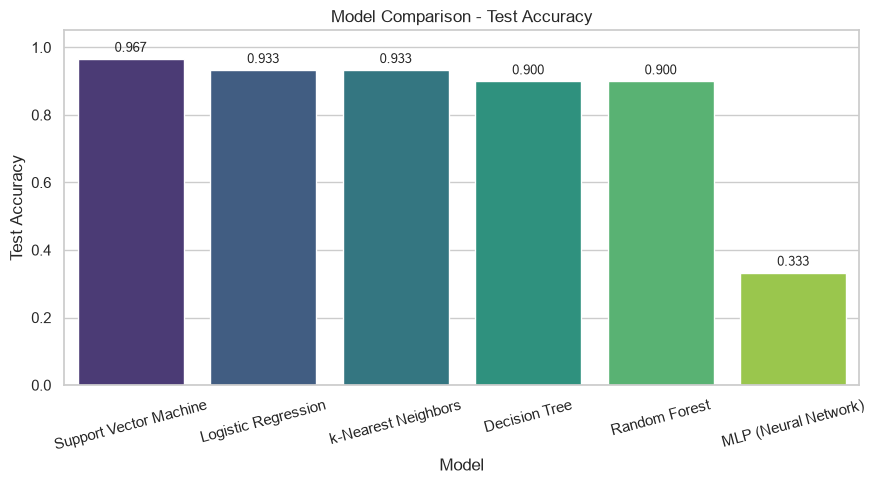

In [9]:
plt.figure(figsize=(9, 5))
sns.barplot(data=results_df, x="Model", y="Test Accuracy", palette="viridis")
plt.ylim(0, 1.05)
plt.xticks(rotation=15)
plt.ylabel("Test Accuracy")
plt.title("Model Comparison - Test Accuracy")
for i, v in enumerate(results_df["Test Accuracy"]):
    plt.text(i, v + 0.02, f"{v:.3f}", ha="center", fontsize=9)
plt.tight_layout()
plt.show()


## 6. Predict on New Samples

Use the best model to predict the species of new (unseen) Iris measurements.

In [10]:
new_samples = np.array([
    [5.1, 3.5, 1.4, 0.2],   # expected: setosa
    [6.7, 3.0, 5.2, 2.3],   # expected: virginica
    [5.9, 3.0, 4.2, 1.5],   # expected: versicolor
    [6.3, 2.8, 5.1, 1.5],   # expected: virginica
    [5.0, 3.4, 1.6, 0.4],   # expected: setosa
])

preds = best_model.predict(new_samples)
probs = best_model.predict_proba(new_samples)

pred_df = pd.DataFrame(new_samples, columns=feature_cols)
pred_df["Predicted Species"] = [class_names[p] for p in preds]
pred_df["Confidence"] = probs.max(axis=1).round(3)

display(pred_df)


,SepalLengthCm,SepalWidthCm,PetalLengthCm,PetalWidthCm,Predicted Species,Confidence
0,5.1,3.5,1.4,0.2,Iris-setosa,0.972
1,6.7,3.0,5.2,2.3,Iris-virginica,0.983
2,5.9,3.0,4.2,1.5,Iris-versicolor,0.964
3,6.3,2.8,5.1,1.5,Iris-versicolor,0.656
4,5.0,3.4,1.6,0.4,Iris-setosa,0.968


## 7. Conclusion

The best-performing model on the Iris dataset was **%s** with a test accuracy of **%.4f**.

Key observations:
- The dataset is small (150 samples) and well-balanced (50 samples per species).
- Petal length and petal width are the most discriminative features (strongest correlation with species).
- Several models achieve near-perfect accuracy, indicating the Iris classes are linearly separable in petal space.
- The MLP (neural network) via scikit-learn serves as the deep-learning component of this task.


In [11]:
best_acc = results_df.iloc[0]["Test Accuracy"]
print("Conclusion summary:")
print(f"Best model: {best_name}")
print(f"Test accuracy: {best_acc:.4f}")
print("Task completed successfully.")


Conclusion summary:
Best model: Support Vector Machine
Test accuracy: 0.9667
Task completed successfully.
